In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
np.random.seed(42)

In [7]:
x=np.linspace(-4,4,400)

create a standard normal distribution

In [8]:
std_normal=stats.norm(0,1)

Verify the 68-95-99.7 rule

In [9]:
print('68-95-99.7 Rule:')
print(f'P(-1<Z<1)={std_normal.cdf(1)-std_normal.cdf(-1):.6f}')
print(f'P(-2<Z<2)={std_normal.cdf(2)-std_normal.cdf(-2):.6f}')
print(f'P(-3<Z<3)={std_normal.cdf(3)-std_normal.cdf(-3):.6f}')

68-95-99.7 Rule:
P(-1<Z<1)=0.682689
P(-2<Z<2)=0.954500
P(-3<Z<3)=0.997300


Z-score standardization

In [13]:
mu_exam, sigma_exam=70,10
for score in [60,70,80,90]:
  z=(score-mu_exam)/sigma_exam
  pct=std_normal.cdf(z)*100
  print(f' Score={score}: z={z:.2f}, Percentile={pct:.1f}%')

 Score=60: z=-1.00, Percentile=15.9%
 Score=70: z=0.00, Percentile=50.0%
 Score=80: z=1.00, Percentile=84.1%
 Score=90: z=2.00, Percentile=97.7%


Create the Exponential Distribution

In [17]:
lam=1.0
exp_dist=stats.expon(scale=1/lam)
print(f'Exp(lam=1): Mean={exp_dist.mean():.4f}, Var={exp_dist.var():.4f}')

#Memoryless Property
print(f'P(X>2)  = {1-exp_dist.cdf(2):.6f}')
print(f'P(X>3)  = {1-exp_dist.cdf(3):.6f}')
print(f'P(X>3|X>1) = {(1-exp_dist.cdf(3))/(1-exp_dist.cdf(1)):.6f}')
print(f'P(X>2|X>1) = {(1-exp_dist.cdf(2))/(1-exp_dist.cdf(1)):.6f}')


Exp(lam=1): Mean=1.0000, Var=1.0000
P(X>2)  = 0.135335
P(X>3)  = 0.049787
P(X>3|X>1) = 0.135335
P(X>2|X>1) = 0.367879


Central limit theorem

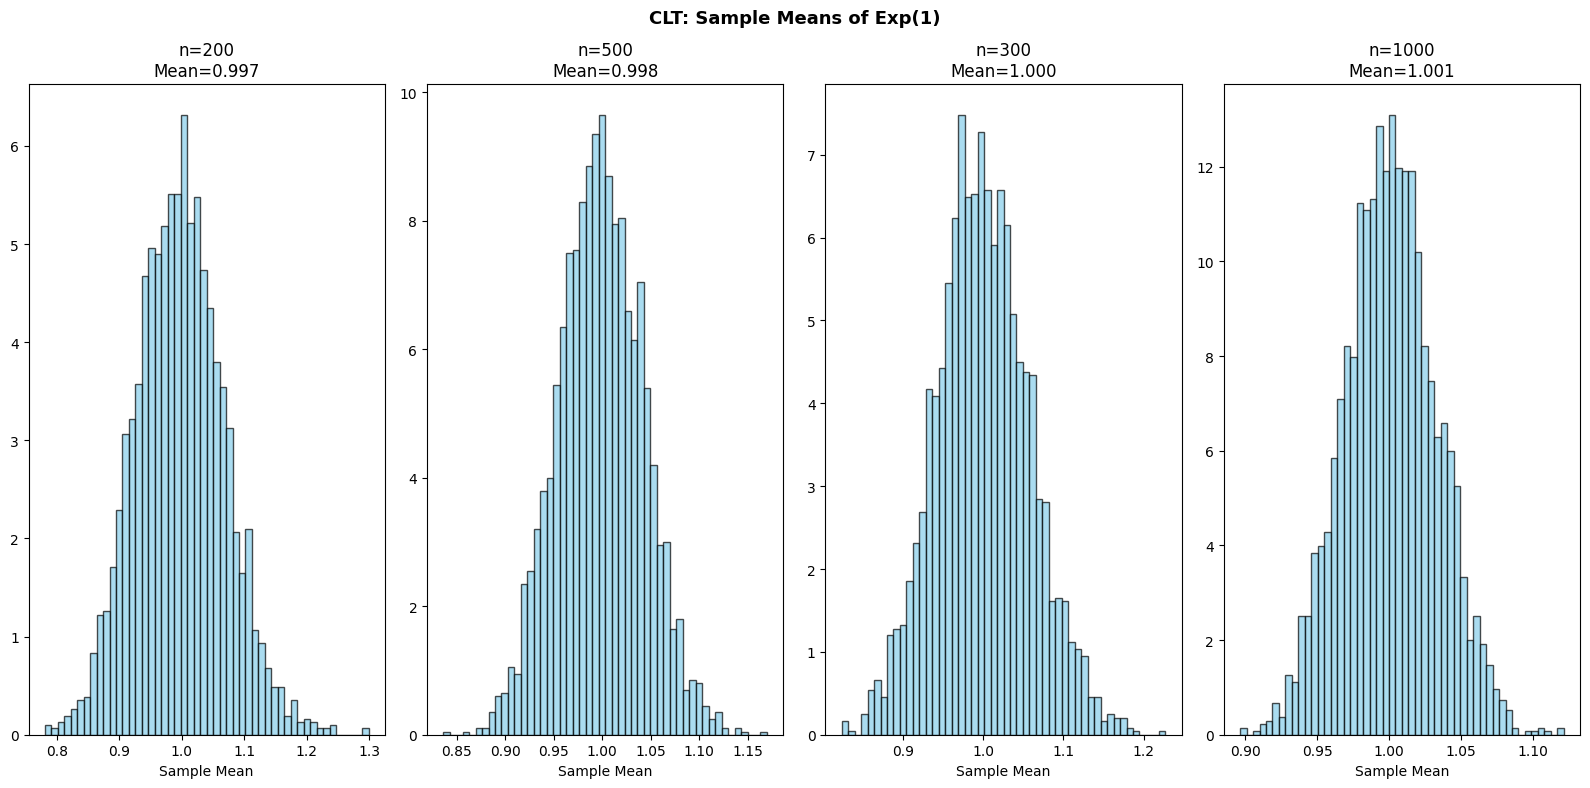

In [25]:
sample_sizes=[200,500,300,1000]
fig, axes=plt.subplots(1,4,figsize=(16,8))

for i, n in enumerate(sample_sizes):
  means=[np.mean(np.random.exponential(1,n)) for _ in range(3000)]
  axes[i].hist(means,bins=50,density=True,
               color='skyblue', edgecolor='black',alpha=0.7)
  axes[i].set_title(f'n={n}\nMean={np.mean(means):.3f}')
  axes[i].set_xlabel('Sample Mean')

fig.suptitle('CLT: Sample Means of Exp(1)', fontsize=13, fontweight='bold')
plt.tight_layout();
plt.show()